In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv("/content/drive/MyDrive/PS_20174392719_1491204439457_log.csv")

print(df.shape)

Mounted at /content/drive
(6362620, 11)


In [ ]:
print("===== Fraud Counts =====")
print(df["isFraud"].value_counts())

print("\n===== Missing Values =====")
print(df.isnull().sum())

print("\n===== Duplicate Rows =====")
print(df.duplicated().sum())

print("\n===== Fraud Percentage =====")
print(df["isFraud"].value_counts(normalize=True) * 100)


===== Fraud Counts =====
isFraud
0    6354407
1       8213
Name: count, dtype: int64

===== Missing Values =====
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

===== Duplicate Rows =====
0

===== Fraud Percentage =====
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


In [ ]:
df["origin_balance_diff"] = df["oldbalanceOrg"] - df["newbalanceOrig"]
df["dest_balance_diff"] = df["newbalanceDest"] - df["oldbalanceDest"]

df["amount_to_oldbalance_ratio"] = df["amount"] / (df["oldbalanceOrg"] + 1)
df["amount_to_destbalance_ratio"] = df["amount"] / (df["oldbalanceDest"] + 1)

df["is_zero_oldbalanceOrg"] = (df["oldbalanceOrg"] == 0).astype(int)
df["is_zero_newbalanceOrig"] = (df["newbalanceOrig"] == 0).astype(int)
df["is_zero_oldbalanceDest"] = (df["oldbalanceDest"] == 0).astype(int)
df["is_zero_newbalanceDest"] = (df["newbalanceDest"] == 0).astype(int)

print(df.shape)

(6362620, 19)


In [ ]:
log_columns = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "origin_balance_diff",
    "dest_balance_diff"
]

for col in log_columns:
    df[col + "_log"] = np.log1p(np.abs(df[col]))

In [ ]:
#Outlier Clipping
#Very extreme values can dominate Logistic Regression. Clipping limits extreme outliers.
def clip_outliers(data, column):
    lower = data[column].quantile(0.01)
    upper = data[column].quantile(0.99)
    data[column] = data[column].clip(lower, upper)

clip_columns = [
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "amount_to_oldbalance_ratio",
    "amount_to_destbalance_ratio"
]

for col in clip_columns:
    clip_outliers(df, col)

In [ ]:
# Drop Unnecessary / Leakage Columns

df = df.drop([col for col in ["nameOrig", "nameDest"] if col in df.columns], axis=1)

# Leakage column, remove it
df = df.drop([col for col in ["isFlaggedFraud"] if col in df.columns], axis=1)

In [ ]:
# One-Hot Encode Transaction Type
#type_TRANSFER → 0/1 type_CASH_OUT → 0/1 type_PAYMENT  → 0/1
if 'type' in df.columns:
    df = pd.get_dummies(df, columns=["type"], drop_first=True)
print(df.shape)

(6362620, 26)


In [ ]:
X = df.drop("isFraud", axis=1).astype("float32")
Y = df["isFraud"].astype("int8")

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y, random_state=42
)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test :", Y_test.shape)

X shape: (6362620, 25)
Y shape: (6362620,)
X_train: (5090096, 25)
X_test : (1272524, 25)
Y_train: (5090096,)
Y_test : (1272524,)


In [ ]:
#StandardScaler makes all features comparable by bringing them to the same scale (mean 0, std 1)
#Scale Features for Autoencoder
scaler_autoencoder = StandardScaler()

X_train_scaled = scaler_autoencoder.fit_transform(X_train).astype("float32")
X_test_scaled = scaler_autoencoder.transform(X_test).astype("float32")

In [ ]:
# Train  AutoEncoder only on normal transactions
X_train_normal = X_train_scaled[Y_train == 0]

input_dim = X_train_scaled.shape[1]

# Autoencoder model
input_layer = Input(shape=(input_dim,))

encoded = Dense(32, activation="relu")(input_layer)
encoded = Dense(8, activation="relu")(encoded)

decoded = Dense(32, activation="relu")(encoded)
output_layer = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(input_layer, output_layer)

# Compile model
autoencoder.compile(optimizer=Adam(0.001), loss="mse")

# Train model
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    shuffle=True
)

Epoch 1/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 62s 3ms/step - loss: 0.0185 - val_loss: 0.0048
Epoch 2/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 80s 3ms/step - loss: 0.0039 - val_loss: 0.0036
Epoch 3/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 50s 3ms/step - loss: 0.0030 - val_loss: 0.0027
Epoch 4/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 63s 4ms/step - loss: 0.0026 - val_loss: 0.0025
Epoch 5/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 78s 3ms/step - loss: 0.0021 - val_loss: 0.0019
Epoch 6/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 73s 3ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 7/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 50s 3ms/step - loss: 0.0017 - val_loss: 0.0016
Epoch 8/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 50s 3ms/step - loss: 0.0016 - val_loss: 0.0015
Epoch 9/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 50s 3ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 10/10
17872/17872 ━━━━━━━━━━━━━━━━━━━━ 48s 3ms/step - loss: 0.0014 - val_loss: 0.0014


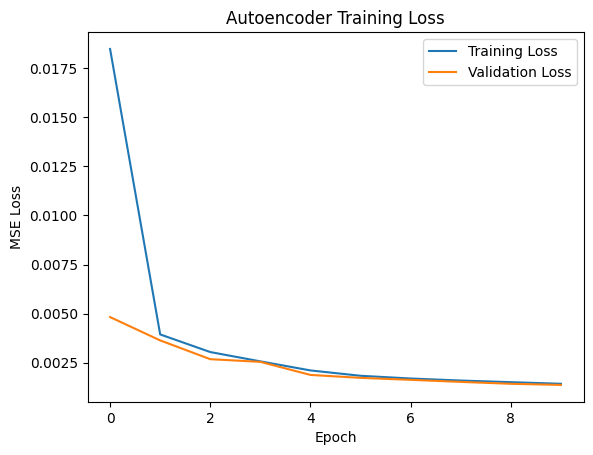

In [ ]:
#Plot Autoencoder Training Loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

In [ ]:
# Reconstruction
train_pred = autoencoder.predict(X_train_scaled, batch_size=1024)
test_pred = autoencoder.predict(X_test_scaled, batch_size=1024)

# Anomaly score (MSE)
train_anomaly_score = np.mean((X_train_scaled - train_pred) ** 2, axis=1)
test_anomaly_score = np.mean((X_test_scaled - test_pred) ** 2, axis=1)

4971/4971 ━━━━━━━━━━━━━━━━━━━━ 19s 4ms/step
1243/1243 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [ ]:
#Combine Anomaly Score with Original Features
#Original transaction features + Autoencoder anomaly score = Hybrid feature set

X_train_hybrid = X_train.copy()
X_test_hybrid = X_test.copy()

X_train_hybrid["autoencoder_anomaly_score"] = train_anomaly_score
X_test_hybrid["autoencoder_anomaly_score"] = test_anomaly_score

X_train_hybrid = X_train_hybrid.astype("float32")
X_test_hybrid = X_test_hybrid.astype("float32")

In [ ]:
#Train Logistic Regression Final Model
logistic_model = LogisticRegression(
    class_weight="balanced",
    solver="saga",
    max_iter=200,
    n_jobs=-1,
    random_state=42
)

logistic_model.fit(X_train_hybrid, Y_train)

LogisticRegression(class_weight='balanced', max_iter=200, n_jobs=-1,
                   random_state=42, solver='saga')

In [ ]:
Y_prob = logistic_model.predict_proba(X_test_hybrid)[:, 1]

threshold = 0.98914343
Y_pred = (Y_prob >= threshold).astype(int)

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, average_precision_score
print("Confusion Matrix:")
print(confusion_matrix(Y_test, Y_pred))

print("\nClassification Report:")
print(classification_report(Y_test, Y_pred))

print("ROC-AUC:", roc_auc_score(Y_test, Y_prob))
print("PR-AUC:", average_precision_score(Y_test, Y_prob))

Confusion Matrix:
[[1270644     237]
 [    823     820]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.78      0.50      0.61      1643

    accuracy                           1.00   1272524
   macro avg       0.89      0.75      0.80   1272524
weighted avg       1.00      1.00      1.00   1272524

ROC-AUC: 0.9785395673419783
PR-AUC: 0.5760159163408648


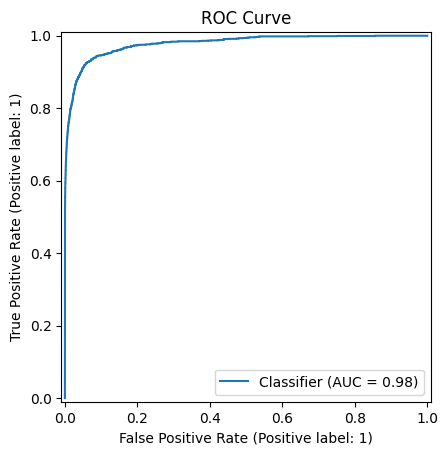

In [ ]:
#ROC Curve

RocCurveDisplay.from_predictions(Y_test, Y_prob)
plt.title("ROC Curve")
plt.show()

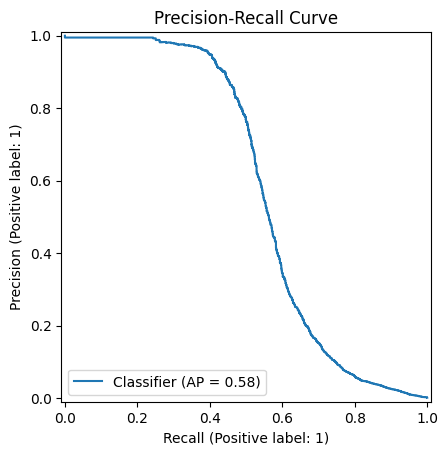

In [ ]:
#Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(Y_test, Y_prob)
plt.title("Precision-Recall Curve")
plt.show()

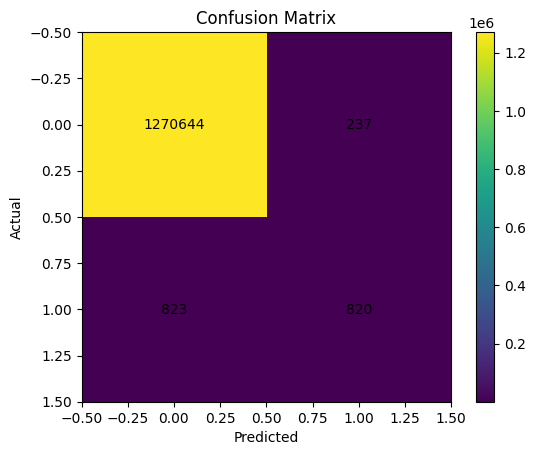

In [ ]:
#Confusion Matrix Plot

cm = confusion_matrix(Y_test, Y_pred)

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [ ]:
#Feature Importance for Logistic Regression

feature_names = X_train_hybrid.columns
coefficients = logistic_model.coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()

top_features = coef_df.sort_values(
    by="abs_coefficient",
    ascending=False
).head(15)

print(top_features)

                        feature   coefficient  abs_coefficient
6           origin_balance_diff  1.106229e-05     1.106229e-05
3                newbalanceOrig -5.908058e-06     5.908058e-06
8    amount_to_oldbalance_ratio -5.275117e-06     5.275117e-06
2                 oldbalanceOrg  5.178424e-06     5.178424e-06
1                        amount -3.826589e-06     3.826589e-06
7             dest_balance_diff -3.386309e-06     3.386309e-06
5                newbalanceDest -1.126079e-06     1.126079e-06
9   amount_to_destbalance_ratio  1.116256e-06     1.116256e-06
4                oldbalanceDest  9.855347e-07     9.855347e-07
0                          step -5.978054e-08     5.978054e-08
14                   amount_log -3.734949e-09     3.734949e-09
16           newbalanceOrig_log -3.727069e-09     3.727069e-09
15            oldbalanceOrg_log -1.866465e-09     1.866465e-09
19      origin_balance_diff_log -1.862752e-09     1.862752e-09
17           oldbalanceDest_log -9.361827e-10     9.361

Main Thing to Understand

The larger the abs_coefficient:

✅ the more important the feature is

The smaller the value:

❌ the less impact it has

In [ ]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(Y_test, Y_prob)

f1_scores = 2 * precision * recall / (precision + recall + 1e-8)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best threshold:", best_threshold)
print("Best precision:", precision[best_index])
print("Best recall:", recall[best_index])
print("Best F1:", f1_scores[best_index])

Best threshold: 0.98914343
Best precision: 0.7757805108798487
Best recall: 0.4990870359099209
Best F1: 0.6074074026429329


In [ ]:
# Train XGBOOST
import xgboost as xgb

#Calculates how imbalanced your dataset is and tells XGBoost to give extra importance to fraud transactions.
scale_pos_weight = (Y_train == 0).sum() / (Y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    objective="binary:logistic",
    n_estimators=50,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train_hybrid, Y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='aucpr', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=50,
              n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
# Predict probabilities using XGBoost
Y_prob_XG = xgb_model.predict_proba(X_test_hybrid)[:, 1]

# Convert probabilities to classes
Y_pred_XG = (Y_prob_XG >= 0.9065396).astype(int)

In [ ]:
# Training probabilities
Y_train_prob_XG = xgb_model.predict_proba(X_train_hybrid)[:, 1]

# Use the same threshold as test set
Y_train_pred_XG = (Y_train_prob_XG >= 0.9581507545896836).astype(int)

# Confusion Matrix
cm_train = confusion_matrix(Y_train, Y_train_pred_XG)
print("Training Confusion Matrix:")
print(cm_train)

# Classification Report
print("\nTraining Classification Report:")
print(classification_report(Y_train, Y_train_pred_XG))

# ROC-AUC
train_roc_auc = roc_auc_score(Y_train, Y_train_prob_XG)
print("\nTraining ROC-AUC:", train_roc_auc)

# PR-AUC
train_pr_auc = average_precision_score(Y_train, Y_train_prob_XG)
print("Training PR-AUC:", train_pr_auc)


print("Confusion Matrix: XGBoost ")
print(confusion_matrix(Y_test, Y_pred_XG))

print("\nClassification Report: XGBoost")
print(classification_report(Y_test, Y_pred_XG))

print("ROC-AUC: XGBoost", roc_auc_score(Y_test, Y_prob_XG))
print("PR-AUC: XGBoost", average_precision_score(Y_test, Y_prob_XG))

Training Confusion Matrix:
[[5083523       3]
 [   1637    4933]]

Training Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   5083526
           1       1.00      0.75      0.86      6570

    accuracy                           1.00   5090096
   macro avg       1.00      0.88      0.93   5090096
weighted avg       1.00      1.00      1.00   5090096


Training ROC-AUC: 0.9999606696095573
Training PR-AUC: 0.9987880792373284
Confusion Matrix: XGBoost 
[[1270880       1]
 [     12    1631]]

Classification Report: XGBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       1.00      0.99      1.00      1643

    accuracy                           1.00   1272524
   macro avg       1.00      1.00      1.00   1272524
weighted avg       1.00      1.00      1.00   1272524

ROC-AUC: XGBoost 0.9998386165118808
PR-AUC: XGBoost 0.9982232822410386


In [ ]:
# Predict probabilities using XGBoost
Y_prob_XG = xgb_model.predict_proba(X_test_hybrid)[:, 1]

# Convert probabilities to classes
Y_pred_XG = (Y_prob_XG >= 0.9581507545896836).astype(int)

print("Confusion Matrix: XGBoost ")
print(confusion_matrix(Y_test, Y_pred_XG))
print(confusion_matrix(Y_test, Y_pred_XG))

print("\nClassification Report: XGBoost")
print(classification_report(Y_test, Y_pred_XG))

print("ROC-AUC: XGBoost", roc_auc_score(Y_test, Y_prob_XG))
print("PR-AUC: XGBoost", average_precision_score(Y_test, Y_prob_XG))

Confusion Matrix: XGBoost 
[[1270880       1]
 [    405    1238]]
[[1270880       1]
 [    405    1238]]

Classification Report: XGBoost
              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       1.00      0.75      0.86      1643

    accuracy                           1.00   1272524
   macro avg       1.00      0.88      0.93   1272524
weighted avg       1.00      1.00      1.00   1272524

ROC-AUC: XGBoost 0.9998386165118808
PR-AUC: XGBoost 0.9982232822410386


True Negatives (TN) = 1,270,880 These are legitimate transactions correctly classified as normal.

False Positives (FP) = 1. These are legitimate transactions incorrectly classified as fraud.

False Negatives (FN) =   451
These are fraudulent transactions incorrectly classified as legitimate.

True Positives (TP) = 1192
These are fraudulent transactions correctly detected.






| AUC | Meaning            |
| --- | ------------------ |
| 0.5 | Random guessing    |
| 0.7 | Good               |
| 0.8 | Very good          |
| 0.9 | Excellent          |
| 1.0 | Perfect separation |


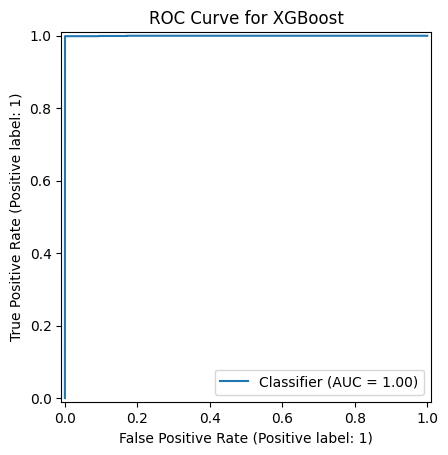

In [ ]:
#ROC Curve

RocCurveDisplay.from_predictions(Y_test, Y_prob_XG)
plt.title("ROC Curve for XGBoost")
plt.show()

| AP  | Meaning   |
| --- | --------- |
| 0.5 | Moderate  |
| 0.7 | Good      |
| 0.9 | Excellent |
| 1.0 | Perfect   |


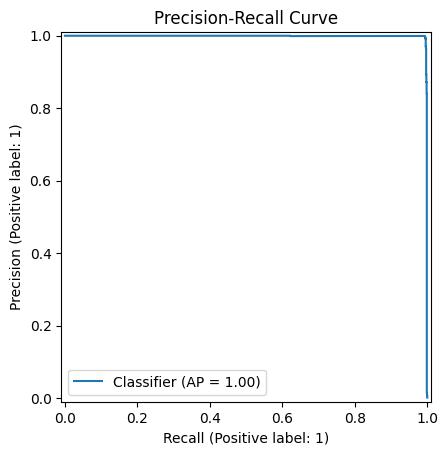

In [ ]:
#Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(Y_test, Y_prob_XG)
plt.title("Precision-Recall Curve")
plt.show()

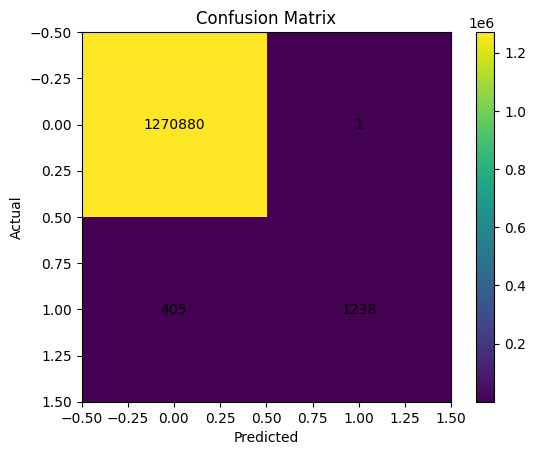

In [ ]:
#Confusion Matrix Plot

cm = confusion_matrix(Y_test, Y_pred_XG)

plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.show()

In [ ]:
precision_XG, recall_XG, thresholds_XG = precision_recall_curve(Y_test, Y_prob_XG)

f1_scores_XG = 2 * precision_XG * recall_XG / (precision_XG + recall_XG + 1e-8)

best_index_XG = np.argmax(f1_scores_XG)
best_threshold_XG = thresholds_XG[best_index_XG]

print("Best threshold:", best_threshold_XG)
print("Best precision:", precision_XG[best_index_XG])
print("Best recall:", recall_XG[best_index_XG])
print("Best F1:", f1_scores_XG[best_index_XG])

Best threshold: 0.8876475
Best precision: 0.9993880048959608
Best recall: 0.9939135727328059
Best F1: 0.9966432662847493
